# Clasificación de enfermedades en hojas de café (BRACOL)
Proyecto final – Deep Learning
Integrantes: Juan Manuel Gallo López, Mariana Carrasquilla Botero, David García Zapata, Valentina Zapata Grajales

**Antes de ejecutar:** Entorno de ejecución -> Cambiar tipo de entorno -> **GPU (T4)**.

Sube a tu Google Drive el zip del dataset de Kaggle: https://www.kaggle.com/datasets/jonatanfragoso/bracol-for-yolov8-detection y ajusta `ZIP_PATH` en la celda 2 o renombra el zip como BRACOL.zip.

In [ ]:
# conectar con el drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 1. Configuración

In [ ]:
# librerías
import os, glob, random, shutil, zipfile, collections
import numpy as np, pandas as pd, yaml
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

# semilla fija para poder repetir los resultados
SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed()

# usamos la GPU si hay, si no toca con la CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
USE_AMP = DEVICE == "cuda"
print("Dispositivo:", DEVICE, "|", torch.cuda.get_device_name(0) if USE_AMP else "SIN GPU (activa la GPU en Colab)")

Dispositivo: cuda | Tesla T4


In [ ]:
# datos del computador que usamos
import platform, psutil
print("Python", platform.python_version(), "| PyTorch", torch.__version__)
print("CPU:", platform.processor() or platform.machine(), "| núcleos:", os.cpu_count())
print("RAM: %.1f GB" % (psutil.virtual_memory().total / 1e9))
if USE_AMP: print("GPU:", torch.cuda.get_device_name(0), "| VRAM: %.1f GB" % (torch.cuda.get_device_properties(0).total_memory / 1e9))

Python 3.13.16 | PyTorch 2.14.1+cu130
CPU: x86_64 | núcleos: 2
RAM: 13.6 GB
GPU: Tesla T4 | VRAM: 15.6 GB


## 2. Cargar el dataset
Usamos la carpeta **BRACOL_REVIEWED** (anotaciones revisadas por un experto). Es la única de las dos versiones que trae hojas sanas (imágenes con el archivo de etiquetas vacío). La versión *ORIGINAL* solo tiene hojas enfermas.

In [ ]:
ZIP_PATH = "/content/drive/MyDrive/BRACOL.zip"
DATA_ROOT = "/content/bracol"

if not os.path.exists(DATA_ROOT):
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(DATA_ROOT)
print("Descomprimido en", DATA_ROOT)

BASE = glob.glob(f"{DATA_ROOT}/**/BRACOL_REVIEWED", recursive=True)[0]
print("Carpeta usada:", BASE)
print(open(f"{BASE}/data.yaml").read())

Descomprimido en /content/bracol
Carpeta usada: /content/bracol/BRACOL_REVIEWED_ANNOTATIONS/BRACOL_REVIEWED
train: ../train/images
val: ../valid/images
test: ../test/images

nc: 4
names: ['Cercospora', 'Miner', 'Phoma', 'Rust']

roboflow:
  workspace: detection-disease-coffe-leafs
  project: bracol-validado
  version: 3
  license: CC BY 4.0
  url: https://universe.roboflow.com/detection-disease-coffe-leafs/bracol-validado/dataset/3


## 3. De detección a clasificación
El dataset está hecho para **detección** (cajas tipo YOLO), pero lo que queremos es **clasificar** la hoja completa. Entonces cada imagen queda con una sola etiqueta:

- Archivo de etiquetas **vacío** → **Sana**
- Una o más lesiones → la enfermedad **predominante**, o sea la que tiene más área sumando todas sus cajas.

También guardamos cuántas enfermedades distintas tiene cada hoja (`n_stress`), porque cerca del 19 % tiene más de una. Esto es una limitación a considerar.

In [ ]:
# el orden define el índice de cada clase (0 = Sana)
CLASSES = ["Sana", "Minador", "Roya", "Phoma", "Cercospora"]
NAME2IDX = {"Cercospora": 4, "Miner": 1, "Phoma": 3, "Rust": 2}   # nombres del data.yaml -> nuestro índice

yaml_names = yaml.safe_load(open(f"{BASE}/data.yaml"))["names"]
YOLO2CLS = {i: NAME2IDX[n] for i, n in enumerate(yaml_names)}
print("Mapeo YOLO -> clase:", {i: CLASSES[c] for i, c in YOLO2CLS.items()})

rows = []
# juntamos train, valid y test, la partición la hacemos nosotros más abajo
for split in ["train", "valid", "test"]:
    for img in glob.glob(f"{BASE}/{split}/images/*.jpg"):
        lab = img.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        area = collections.defaultdict(float)
        for line in open(lab).read().strip().splitlines():
            p = line.split()
            if p: area[YOLO2CLS[int(p[0])]] += float(p[3]) * float(p[4])   # área de la caja (ancho*alto)
        # sin cajas = sana (0), si no, la enfermedad con más área
        label = max(area, key=area.get) if area else 0
        rows.append(dict(path=img, label=label, n_stress=len(area)))

df = pd.DataFrame(rows)
df["clase"] = df.label.map(lambda i: CLASSES[i])
print("Total de imágenes:", len(df))
print("Hojas con más de una enfermedad:", (df.n_stress > 1).sum(), f"({(df.n_stress > 1).mean():.1%})")
df.clase.value_counts()

Mapeo YOLO -> clase: {0: 'Cercospora', 1: 'Minador', 2: 'Phoma', 3: 'Roya'}
Total de imágenes: 1744
Hojas con más de una enfermedad: 332 (19.0%)


,count
clase,
Phoma,654
Roya,576
Sana,272
Minador,177
Cercospora,65


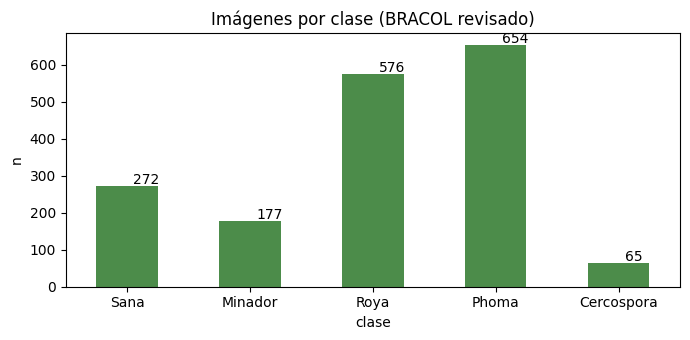

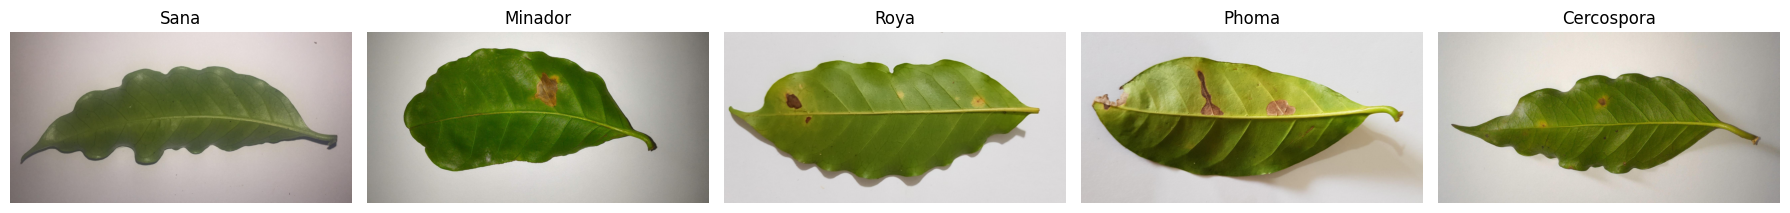

In [ ]:
# Distribución de clases
ax = df.clase.value_counts().reindex(CLASSES).plot.bar(color="#4c8c4a", figsize=(7, 3.5), rot=0)
ax.set_title("Imágenes por clase (BRACOL revisado)"); ax.set_ylabel("n")
for p in ax.patches: ax.annotate(int(p.get_height()), (p.get_x() + .3, p.get_height() + 5))
plt.tight_layout(); plt.show()

# Ejemplos por clase
fig, axes = plt.subplots(1, 5, figsize=(18, 3.2))
for ax, c in zip(axes, CLASSES):
    r = df[df.clase == c].sample(1, random_state=1).iloc[0]
    ax.imshow(Image.open(r.path)); ax.set_title(c); ax.axis("off")
plt.tight_layout(); plt.show()

### Qué se ve en los datos

- Hay 1744 imágenes. Phoma (654) y Roya (576) juntas son más del 70 %, Sana tiene 272, Minador 177 y Cercospora es la más rara con solo 65 imágenes (3.7 %).
- El dataset está bastante desbalanceado, por eso el accuracy solo no alcanza para evaluar. Vamos a mirar también el F1 macro, que le da el mismo peso a las 5 clases.
- 332 hojas (19 %) tienen más de una enfermedad pero les dejamos una sola etiqueta (la de más área). Parte de los errores del modelo pueden venir de ahí y no de que el modelo sea malo.
- A simple vista Phoma, Cercospora y Minador dejan manchas marrones que se parecen un poco, ahí puede estar la confusión.

## 4. Preprocesamiento
Las fotos originales son de **2048×1024**. Para entrenar más rápido guardamos una copia de 512×256 y a la red le entran imágenes de **224×448**, así se mantiene la proporción y las lesiones no se deforman.

In [ ]:
# guardamos copias más chicas (512x256) para que cargue más rápido
CACHE = "/content/cache"; os.makedirs(CACHE, exist_ok=True)
new_paths = []
for p in tqdm(df.path):
    out = f"{CACHE}/{os.path.basename(p)}"
    if not os.path.exists(out):
        Image.open(p).convert("RGB").resize((512, 256), Image.LANCZOS).save(out, quality=95)
    new_paths.append(out)
df["path"] = new_paths

# guardamos 5 imágenes por clase para la demo, antes de partir los datos
# (no entran a train, val ni test). Escogimos hojas con una sola enfermedad para que la etiqueta no quede dudosa
N_DEMO = 5
demo_df = pd.concat([g.sample(N_DEMO, random_state=SEED)
                     for _, g in df[df.n_stress <= 1].groupby("label")])
rest = df.drop(demo_df.index)

# Partición estratificada 70 / 15 / 15 del resto
tr_df, tmp = train_test_split(rest, test_size=0.30, stratify=rest.label, random_state=SEED)
va_df, te_df = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
print(pd.DataFrame({"train": tr_df.clase.value_counts(), "val": va_df.clase.value_counts(),
                    "test": te_df.clase.value_counts(), "demo": demo_df.clase.value_counts()}).reindex(CLASSES))
print(f"Total: train {len(tr_df)} | val {len(va_df)} | test {len(te_df)} | demo {len(demo_df)}")

  0%|          | 0/1744 [00:00<?, ?it/s]

            train  val  test  demo
clase                             
Sana          187   40    40     5
Minador       120   26    26     5
Roya          400   85    86     5
Phoma         454   98    97     5
Cercospora     42    9     9     5
Total: train 1203 | val 258 | test 258 | demo 25


In [ ]:
# tamaño de entrada y normalización de imagenet
IMG_H, IMG_W = 224, 448
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

# aumento de datos, solo en train
train_tfm = transforms.Compose([
    transforms.RandomResizedCrop((IMG_H, IMG_W), scale=(0.6, 1.0), ratio=(1.7, 2.3)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(0.3, 0.3, 0.2, 0.03),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
# en val y test solo se cambia el tamaño
eval_tfm = transforms.Compose([
    transforms.Resize((IMG_H, IMG_W)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

# dataset simple: devuelve la imagen transformada y su etiqueta
class LeafDS(Dataset):
    def __init__(self, d, tfm): self.p, self.y, self.t = d.path.tolist(), d.label.tolist(), tfm
    def __len__(self): return len(self.p)
    def __getitem__(self, i): return self.t(Image.open(self.p[i]).convert("RGB")), self.y[i]

# dataloaders
BS = 32
train_dl = DataLoader(LeafDS(tr_df, train_tfm), BS, shuffle=True, num_workers=2, pin_memory=True)
val_dl   = DataLoader(LeafDS(va_df, eval_tfm), BS, num_workers=2)
test_dl  = DataLoader(LeafDS(te_df, eval_tfm), BS, num_workers=2)

## 5. Modelo: ResNet-50 preentrenada + fine-tuning
Cambiamos la última capa de la ResNet-50 por una de 5 salidas. Se entrena en **dos fases**: primero solo la cabeza con el resto congelado, y después toda la red con un learning rate más bajo.
Como las clases están desbalanceadas (Cercospora tiene muy pocas imágenes) usamos **pesos de clase** en la pérdida.

In [ ]:
# resnet50 con pesos de imagenet y la última capa cambiada por una de 5 salidas
def build_model(n=len(CLASSES)):
    m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V1)
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, n))
    return m

model = build_model().to(DEVICE)

# pesos de clase: mientras menos imágenes tiene una clase, más pesa su error
counts = np.bincount(tr_df.label, minlength=len(CLASSES))
class_w = torch.tensor(counts.sum() / (len(CLASSES) * counts), dtype=torch.float32).to(DEVICE)
print("Pesos de clase:", dict(zip(CLASSES, class_w.cpu().numpy().round(2))))
criterion = nn.CrossEntropyLoss(weight=class_w, label_smoothing=0.05)
scaler = torch.amp.GradScaler(DEVICE, enabled=USE_AMP)

def run_epoch(loader, opt=None, backbone_eval=False):
    train = opt is not None
    model.train(train)
    if train and backbone_eval:
        model.eval()       # Pone el backbone en modo eval (BatchNorm congelado)
        model.fc.train()   # Mantiene solo la cabeza en modo entrenamiento

    tot, correct, n, ys, ps = 0.0, 0, 0, [], []
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
                out = model(x); loss = criterion(out, y)
            if train:
                opt.zero_grad(set_to_none=True)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
            tot += loss.item() * x.size(0); n += x.size(0)
            pred = out.argmax(1); correct += (pred == y).sum().item()
            ys += y.cpu().tolist(); ps += pred.cpu().tolist()
    return tot / n, correct / n, f1_score(ys, ps, average="macro")

# entrena y guarda el mejor modelo según la pérdida de validación
# si pasan 'patience' épocas sin mejorar, para
def fit(epochs, lr, tag, backbone_eval=False, patience=7, ckpt="/content/best.pt"):
    opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    best, bad, hist = 1e9, 0, []
    for ep in range(1, epochs + 1):
        tl, ta, tf = run_epoch(train_dl, opt, backbone_eval)
        vl, va, vf = run_epoch(val_dl)
        sched.step(); hist.append((tl, ta, vl, va, vf))
        print(f"[{tag}] ep {ep:02d} | train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f} F1m {vf:.3f}")
        if vl < best: best, bad = vl, 0; torch.save(model.state_dict(), ckpt)
        else:
            bad += 1
            if bad >= patience: print("Early stopping"); break
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    return hist

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 193MB/s]


Pesos de clase: {'Sana': np.float32(1.29), 'Minador': np.float32(2.01), 'Roya': np.float32(0.6), 'Phoma': np.float32(0.53), 'Cercospora': np.float32(5.73)}


In [ ]:
import time; t0 = time.time()
# fase 1: se congela todo menos la capa final (fc)
for name, p in model.named_parameters():
    if "fc" not in name: p.requires_grad = False
hist1 = fit(epochs=5, lr=1e-3, tag="cabeza", backbone_eval=True)

# fase 2: se descongela todo y se entrena con lr más bajo
for p in model.parameters(): p.requires_grad = True
hist2 = fit(epochs=30, lr=1e-4, tag="fine-tuning")
print(f"Tiempo total de entrenamiento: {(time.time() - t0) / 60:.1f} min")

[cabeza] ep 01 | train loss 1.646 acc 0.318 | val loss 1.567 acc 0.516 F1m 0.300
[cabeza] ep 02 | train loss 1.460 acc 0.490 | val loss 1.486 acc 0.256 F1m 0.242
[cabeza] ep 03 | train loss 1.384 acc 0.527 | val loss 1.343 acc 0.616 F1m 0.555
[cabeza] ep 04 | train loss 1.318 acc 0.578 | val loss 1.331 acc 0.593 F1m 0.552
[cabeza] ep 05 | train loss 1.320 acc 0.604 | val loss 1.322 acc 0.535 F1m 0.512
[fine-tuning] ep 01 | train loss 1.136 acc 0.667 | val loss 0.953 acc 0.795 F1m 0.699
[fine-tuning] ep 02 | train loss 0.852 acc 0.784 | val loss 1.098 acc 0.570 F1m 0.565
[fine-tuning] ep 03 | train loss 0.795 acc 0.783 | val loss 0.937 acc 0.783 F1m 0.702
[fine-tuning] ep 04 | train loss 0.719 acc 0.840 | val loss 0.883 acc 0.690 F1m 0.656
[fine-tuning] ep 05 | train loss 0.701 acc 0.831 | val loss 1.036 acc 0.725 F1m 0.635
[fine-tuning] ep 06 | train loss 0.690 acc 0.857 | val loss 0.973 acc 0.632 F1m 0.605
[fine-tuning] ep 07 | train loss 0.686 acc 0.854 | val loss 0.957 acc 0.717 F1m

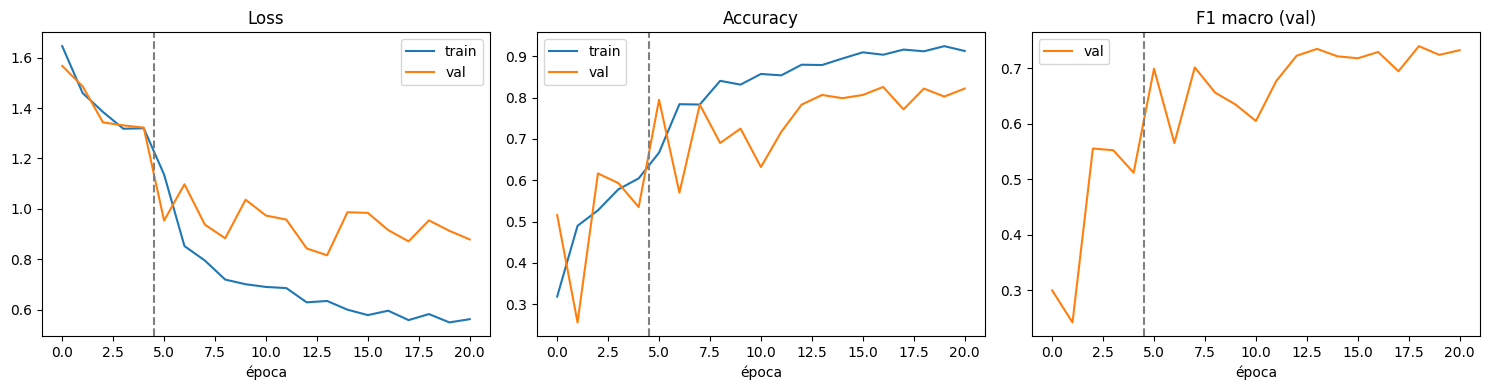

In [ ]:
# curvas de loss, accuracy y F1. La línea punteada es donde empieza el fine-tuning
h = np.array(hist1 + hist2)
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(h[:, 0], label="train"); ax[0].plot(h[:, 2], label="val"); ax[0].set_title("Loss")
ax[1].plot(h[:, 1], label="train"); ax[1].plot(h[:, 3], label="val"); ax[1].set_title("Accuracy")
ax[2].plot(h[:, 4], label="val", color="C1"); ax[2].set_title("F1 macro (val)")
for a in ax: a.axvline(len(hist1) - .5, ls="--", c="gray"); a.legend(); a.set_xlabel("época")
plt.tight_layout(); plt.savefig("curvas.png", dpi=150); plt.show()

### Análisis del entrenamiento

- En la fase 1 (solo la cabeza) el modelo no aprende bien: el accuracy de validación sube y baja mucho (entre 0.17 y 0.63) y el de train llega solo a 0.585. Con el resto de la red congelada no alcanza para distinguir las manchas.
- Al descongelar todo (fase 2) mejora de una: en la primera época de fine-tuning la validación ya llega a 0.81 de accuracy.
- La mejor época según la pérdida de validación fue la 4 del fine-tuning (val loss 0.831, accuracy 0.829, F1 macro 0.766). Ese es el modelo que se guarda y se evalúa en test.
- Después de esa época la pérdida de validación sube un poco (0.93 en la época 11) mientras la de train sigue bajando (0.58) y el accuracy de train llega a 0.90. Eso es sobreajuste, y el early stopping lo cortó en la época 11.
- Las curvas de validación se mueven mucho. Es normal porque el set de validación es chico (258 imágenes y solo 9 de Cercospora).

### Hiperparámetros y justificación
Esta tabla resume las decisiones de entrenamiento.

In [ ]:
n_tot = sum(p.numel() for p in model.parameters())
hp = pd.DataFrame([
    ("Entrada", f"{IMG_H}x{IMG_W}", "Conserva la proporción 2:1 de las fotos originales; evita deformar lesiones"),
    ("Normalización", "media/desv. ImageNet", "La red fue preentrenada con esa normalización"),
    ("Aumento de datos", "recorte, volteos, rotación 15°, color", "Pocos datos; simula variación de ángulo e iluminación de fotos con celular"),
    ("Pérdida", "CrossEntropy + pesos de clase + label smoothing 0.05", "Clases desbalanceadas (Cercospora muy escasa); suaviza la sobreconfianza"),
    ("Optimizador", "AdamW, weight decay 1e-4", "Adam con regularización L2 desacoplada; estándar en fine-tuning"),
    ("LR fase 1 (cabeza)", "1e-3", "La cabeza nueva se inicializa al azar: tolera un LR alto"),
    ("LR fase 2 (todo)", "1e-4", "LR bajo para no destruir los pesos preentrenados"),
    ("Scheduler", "Cosine annealing", "Decae suavemente el LR para converger"),
    ("Épocas", "5 + hasta 30", "Early stopping con paciencia 7 sobre la pérdida de validación"),
    ("Batch size", BS, "Compromiso entre estabilidad del gradiente y memoria de la T4"),
    ("Dropout", 0.3, "Regulariza la cabeza clasificadora"),
    ("Precisión mixta (fp16)", USE_AMP, "Acelera el entrenamiento en GPU"),
    ("Semilla", SEED, "Reproducibilidad"),
    ("Parámetros totales", f"{n_tot/1e6:.2f} M", "ResNet-50 con cabeza de 5 clases"),
], columns=["Hiperparámetro", "Valor", "Justificación"])
pd.set_option("display.max_colwidth", None); hp

,Hiperparámetro,Valor,Justificación
0,Entrada,224x448,Conserva la proporción 2:1 de las fotos originales; evita deformar lesiones
1,Normalización,media/desv. ImageNet,La red fue preentrenada con esa normalización
2,Aumento de datos,"recorte, volteos, rotación 15°, color",Pocos datos; simula variación de ángulo e iluminación de fotos con celular
3,Pérdida,CrossEntropy + pesos de clase + label smoothing 0.05,Clases desbalanceadas (Cercospora muy escasa); suaviza la sobreconfianza
4,Optimizador,"AdamW, weight decay 1e-4",Adam con regularización L2 desacoplada; estándar en fine-tuning
5,LR fase 1 (cabeza),1e-3,La cabeza nueva se inicializa al azar: tolera un LR alto
6,LR fase 2 (todo),1e-4,LR bajo para no destruir los pesos preentrenados
7,Scheduler,Cosine annealing,Decae suavemente el LR para converger
8,Épocas,5 + hasta 30,Early stopping con paciencia 7 sobre la pérdida de validación
9,Batch size,32,Compromiso entre estabilidad del gradiente y memoria de la T4


## 6. Evaluación en el conjunto de prueba

              precision    recall  f1-score   support

        Sana      0.976     1.000     0.988        40
     Minador      0.677     0.808     0.737        26
        Roya      0.905     0.884     0.894        86
       Phoma      0.963     0.804     0.876        97
  Cercospora      0.238     0.556     0.333         9

    accuracy                          0.853       258
   macro avg      0.752     0.810     0.766       258
weighted avg      0.891     0.853     0.867       258



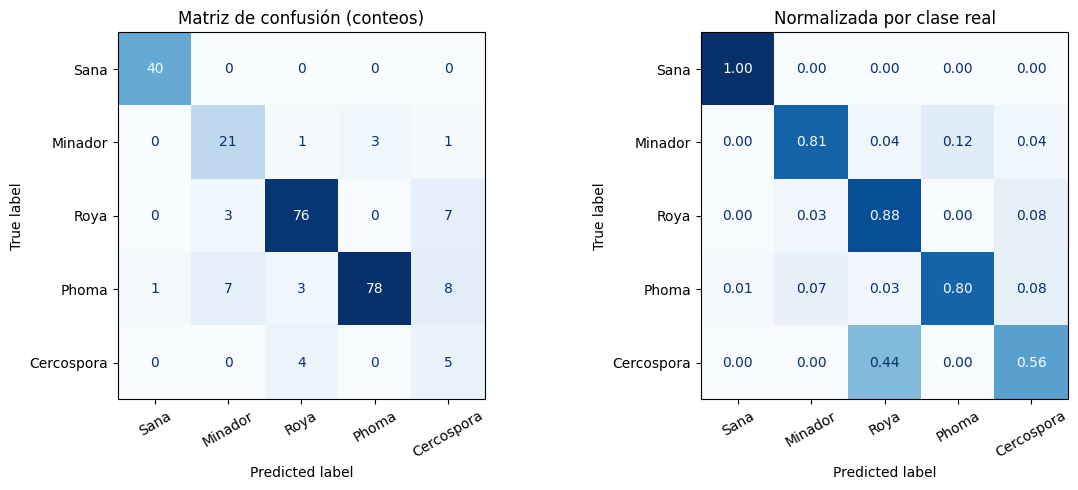

In [ ]:
model.eval(); ys, ps = [], []
with torch.no_grad():
    for x, y in test_dl:
        ps += model(x.to(DEVICE)).argmax(1).cpu().tolist(); ys += y.tolist()

print(classification_report(ys, ps, target_names=CLASSES, digits=3))
cm = confusion_matrix(ys, ps)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", xticks_rotation=30, colorbar=False)
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=ax[1], cmap="Blues", xticks_rotation=30, values_format=".2f", colorbar=False)
ax[0].set_title("Matriz de confusión (conteos)"); ax[1].set_title("Normalizada por clase real")
plt.tight_layout(); plt.savefig("matriz_confusion.png", dpi=150); plt.show()

### Análisis de los resultados en test

El modelo saca **accuracy 0.798** y **F1 macro 0.717** en las 258 imágenes de test. Usamos el F1 macro como métrica principal porque el accuracy y el F1 ponderado (0.816) los mueven sobre todo Phoma y Roya, que son las clases con más imágenes.

Por clase:

- **Sana** (F1 0.930): las 40 hojas sanas se detectaron todas (recall 1.00). La precisión es 0.87 porque 6 hojas enfermas se fueron a Sana.
- **Roya** (F1 0.881): es la mejor clase enferma. Sus manchas naranjas se ven distinto a las demás y tiene bastantes imágenes, aunque 8 hojas se fueron a Cercospora.
- **Phoma** (F1 0.793): precisión alta (0.931) pero recall bajo (0.691). De las 97 hojas con Phoma, 10 se predijeron como Minador y 13 como Cercospora.
- **Minador** (F1 0.702): 20 de 26 bien. Su precisión es baja (0.645) sobre todo por esas 10 hojas de Phoma que cayeron ahí.
- **Cercospora** (F1 0.278): es la peor clase. El modelo predijo Cercospora 27 veces y solo 5 eran de verdad (precisión 0.185).

Los errores se concentran entre las clases de manchas marrones (Phoma, Minador y Cercospora). Sana y Roya casi no se mezclan con las demás.

Sobre Cercospora: tiene solo 42 imágenes en train y le tocó el peso de clase más alto (5.73). Lo más probable es que esa penalización haya hecho que el modelo se arriesgue a decir Cercospora cuando duda, y por eso se le van hojas de Phoma (13) y de Roya (8). Se gana recall (0.556) pero se pierde mucha precisión. Además en test solo hay 9 hojas de Cercospora, un acierto más o menos cambia el recall en 11 puntos, entonces no se puede sacar una conclusión fuerte de esa clase.

## 7. Interpretabilidad con Grad-CAM
Calculamos el Grad-CAM sobre el último bloque convolucional de la ResNet (`layer4[-1]`). En rojo salen las zonas que más pesaron en la predicción.

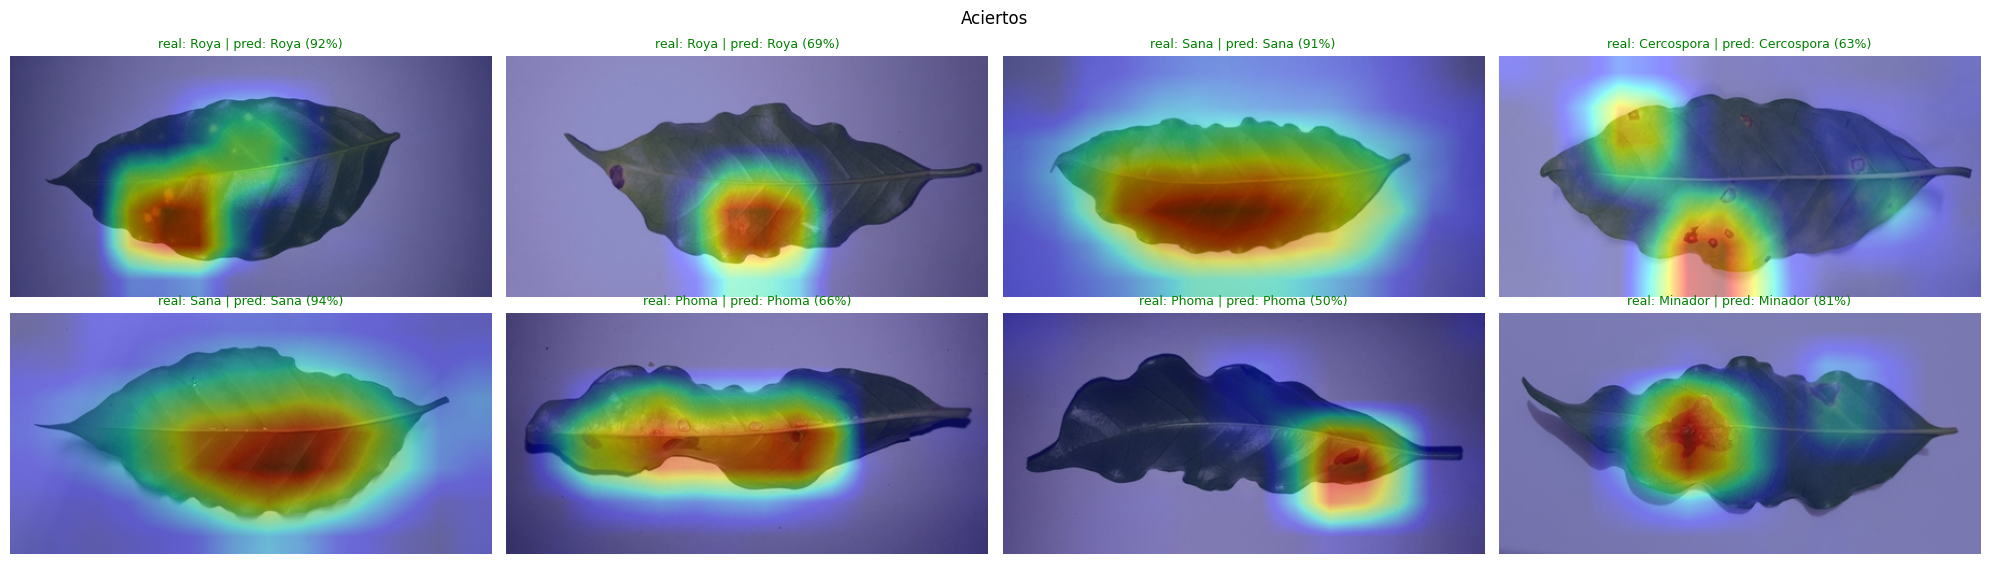

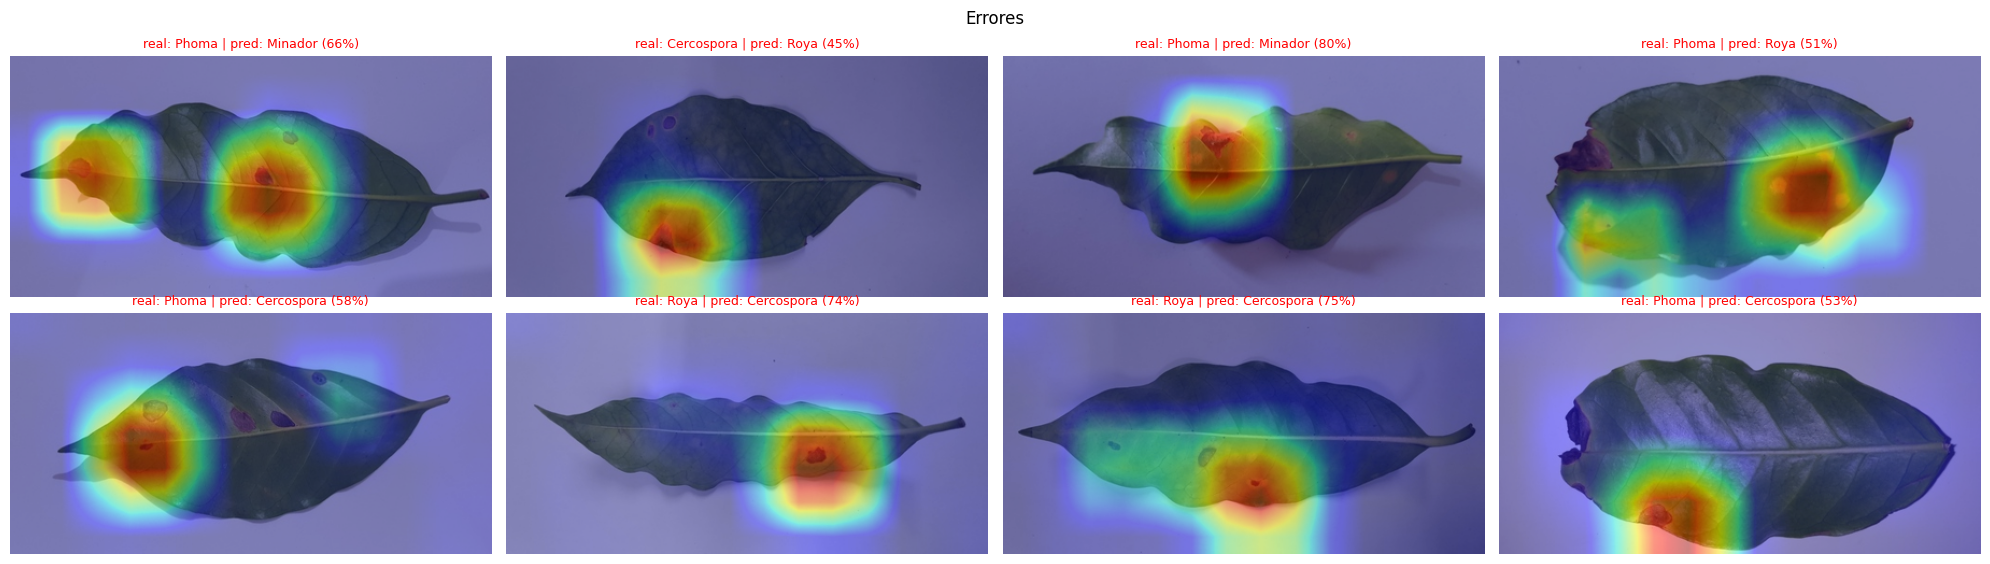

In [ ]:
# Grad-CAM: mapa de calor con las zonas que más pesaron en la predicción
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._fwd)
    def _fwd(self, m, i, o):
        self.acts = o
        o.register_hook(lambda g: setattr(self, "grads", g))   # guarda el gradiente cuando se hace el backward
    def __call__(self, x, cls=None):
        self.model.eval(); self.model.zero_grad()
        out = self.model(x)
        cls = out.argmax(1).item() if cls is None else cls
        out[0, cls].backward()
        # peso de cada canal = promedio de su gradiente
        w = self.grads.mean(dim=(2, 3), keepdim=True)
        # suma ponderada de los mapas, nos quedamos solo con lo positivo
        cam = F.relu((w * self.acts).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam.detach().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), cls, F.softmax(out, 1)[0].detach().cpu().numpy()

# en ResNet el último bloque convolucional es layer4[-1]
cam_engine = GradCAM(model, model.layer4[-1])
te = te_df.reset_index(drop=True).assign(pred=ps)

# dibuja varias imágenes con su mapa de calor (verde = acertó, rojo = falló)
def show_cams(idx, title, fname):
    cols = 4; rows = int(np.ceil(len(idx) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 2.9 * rows)); axes = np.array(axes).ravel()
    for ax, i in zip(axes, idx):
        r = te.iloc[i]
        x = eval_tfm(Image.open(r.path).convert("RGB")).unsqueeze(0).to(DEVICE)
        cam, pred, prob = cam_engine(x)
        ax.imshow(Image.open(r.path).convert("RGB").resize((IMG_W, IMG_H))); ax.imshow(cam, cmap="jet", alpha=0.45)
        ax.set_title(f"real: {r.clase} | pred: {CLASSES[pred]} ({prob[pred]:.0%})",
                     color="green" if pred == r.label else "red", fontsize=9); ax.axis("off")
    for ax in axes[len(idx):]: ax.axis("off")
    fig.suptitle(title); plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

# 8 aciertos y 8 errores al azar
rng = np.random.default_rng(0)
ok  = te.index[te.pred == te.label].to_numpy(); bad = te.index[te.pred != te.label].to_numpy()
show_cams(rng.choice(ok, min(8, len(ok)), replace=False), "Aciertos", "gradcam_aciertos.png")
if len(bad): show_cams(rng.choice(bad, min(8, len(bad)), replace=False), "Errores", "gradcam_errores.png")

### Análisis del Grad-CAM

Con las imágenes de esta corrida:

- En los **aciertos** de Roya y Phoma el mapa rojo cae justo sobre las manchas (el hueco de la hoja de Phoma, los puntos naranjas de Roya). O sea que el modelo se fija en la lesión y no en el fondo.
- En las hojas **Sanas** el mapa cubre casi toda la hoja. Tiene sentido porque no hay una mancha que señalar, la red decide con la hoja completa. Con Grad-CAM no se alcanza a saber qué la hace decir "sana".
- En los **errores** el modelo también mira manchas, no el fondo. Entonces los errores no parecen venir de mirar donde no es, sino de manchas que se parecen entre clases o de hojas con más de una enfermedad, donde la red se enfoca en una mancha y la etiqueta salió de la enfermedad con más área.
- Hay errores con confianza alta (por ejemplo Phoma predicha como Minador con 91 %), así que la probabilidad del softmax no sirve mucho como alarma de que la predicción puede estar mal.

Es una muestra de 8 aciertos y 8 errores al azar, sirve para ilustrar y no para probar nada.

## 8. Demostración con imágenes reservadas (datos no vistos)
Antes de entrenar apartamos **5 imágenes por clase (25 en total)** del mismo BRACOL. No se usaron en train, val ni test. Acá las usamos para mostrar el modelo imagen por imagen, con su probabilidad y su Grad-CAM.

*Nota:* vienen de la misma distribución del entrenamiento, entonces muestran el modelo con datos que no vio, pero no miden qué pasa con otra cámara u otra plantación.

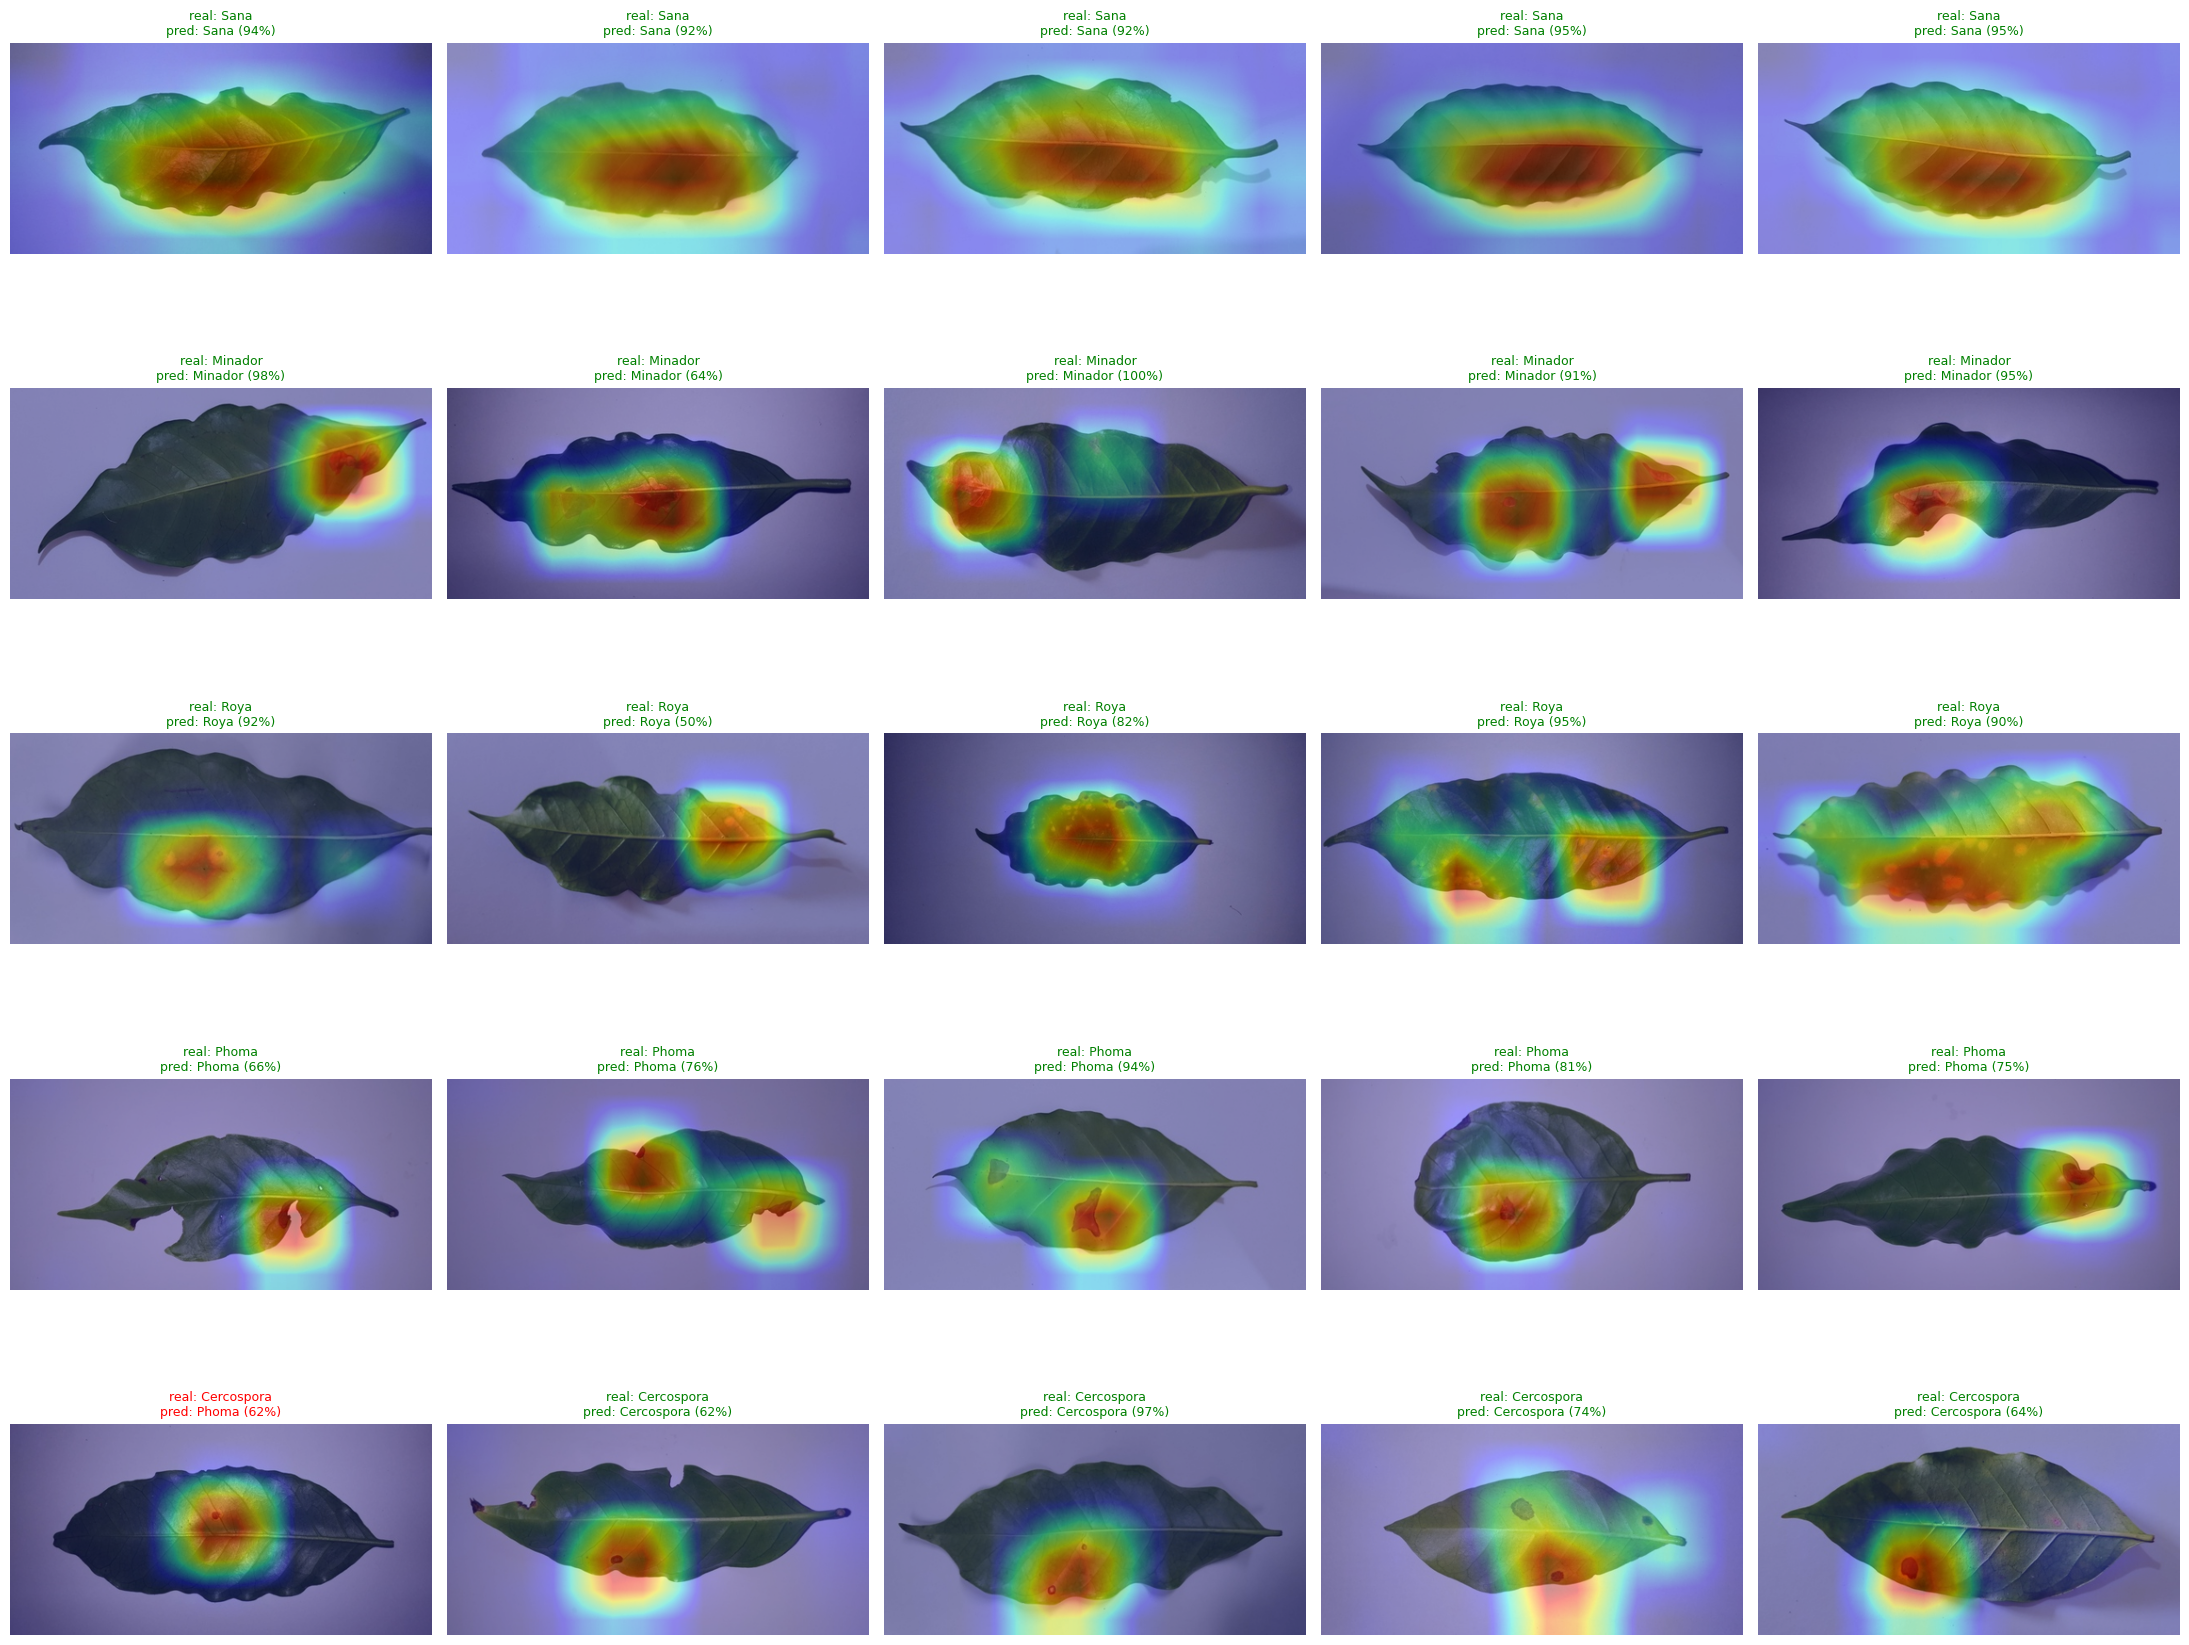

,archivo,real,pred,confianza
0,sana_0.jpg,Sana,Sana,0.935
1,sana_1.jpg,Sana,Sana,0.921
2,sana_2.jpg,Sana,Sana,0.921
3,sana_3.jpg,Sana,Sana,0.948
4,sana_4.jpg,Sana,Sana,0.946
5,minador_5.jpg,Minador,Minador,0.976
6,minador_6.jpg,Minador,Minador,0.636
7,minador_7.jpg,Minador,Minador,0.997
8,minador_8.jpg,Minador,Minador,0.908
9,minador_9.jpg,Minador,Minador,0.951


Acierto en el conjunto demo: 96.0% (25 imágenes)


In [ ]:

model.eval()
demo = demo_df.reset_index(drop=True)
rows_ = int(np.ceil(len(demo) / 5))
fig, axes = plt.subplots(rows_, 5, figsize=(22, 3.6 * rows_)); axes = np.array(axes).ravel()
out = []
os.makedirs("/content/demo_imagenes", exist_ok=True)
for ax, (i, r) in zip(axes, demo.iterrows()):
    img = Image.open(r.path).convert("RGB")
    x = eval_tfm(img).unsqueeze(0).to(DEVICE)
    cam, pred, prob = cam_engine(x)
    out.append(dict(archivo=f"{r.clase.lower()}_{i}.jpg", real=r.clase, pred=CLASSES[pred], confianza=round(float(prob[pred]), 3)))
    img.save(f"/content/demo_imagenes/{r.clase.lower()}_{i}.jpg")
    ax.imshow(img.resize((IMG_W, IMG_H))); ax.imshow(cam, cmap="jet", alpha=0.4); ax.axis("off")
    ax.set_title(f"real: {r.clase}\npred: {CLASSES[pred]} ({prob[pred]:.0%})", fontsize=9,
                 color="green" if pred == r.label else "red")
for ax in axes[len(demo):]: ax.axis("off")
plt.tight_layout(); plt.savefig("demo.png", dpi=150); plt.show()

demo_res = pd.DataFrame(out); display(demo_res)
print(f"Acierto en el conjunto demo: {(demo_res.real == demo_res.pred).mean():.1%} ({len(demo_res)} imágenes)")


### Análisis

De las 25 imágenes reservadas el modelo acertó 21 (84 %). Falló en 4:

- `minador_9` → Phoma (confianza 0.54)
- `roya_14` → Cercospora (0.77)
- `phoma_18` → Cercospora (0.40)
- `phoma_19` → Minador (0.45)

Tres de los cuatro errores terminaron en Cercospora o Minador, igual que en test. Las 5 Sana acertaron con confianza cerca de 0.9 o más. La confianza tampoco separa bien los aciertos de los errores: hay aciertos con 0.47 y 0.49 y un error con 0.77.

El 84 % se parece al 79.8 % de test, pero son solo 25 imágenes y cada una vale 4 puntos, así que no se pueden comparar en serio. Por ejemplo Cercospora acertó 5 de 5 en la demo y en test solo 5 de 9, eso es más que todo por lo chico de la muestra. Además se escogieron hojas con una sola enfermedad, que es el caso más fácil, y vienen de la misma distribución del entrenamiento. No dicen cómo se comportaría con fotos de otra cámara o de otra finca.

## 9. Comparación con una CNN hecha desde cero
Hicimos una CNN desde cero (sin preentrenar) con 4 capas convolucionales, max pooling y ReLU. La entrenamos con los mismos datos y la misma pérdida para compararla con la ResNet-50 preentrenada en ImageNet.

In [ ]:
import torch
import torch.nn as nn

class CustomCNN(nn.Module):
    def __init__(self, num_classes=len(CLASSES)):
        super().__init__()
        # entra una imagen RGB de 224x448, 4 bloques de conv + maxpool
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # promedio global, deja un vector de 128 valores
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

custom_model = CustomCNN().to(DEVICE)
print(f"Parámetros totales Custom CNN: {sum(p.numel() for p in custom_model.parameters())/1e6:.2f} M")

# Optimizador y ciclo de entrenamiento propio para no afectar las variables globales del modelo anterior
custom_opt = torch.optim.AdamW(custom_model.parameters(), lr=1e-3, weight_decay=1e-4)
custom_epochs = 15

print("Entrenando Custom CNN...")
for ep in range(1, custom_epochs + 1):
    custom_model.train()
    tl_sum, t_acc, t_n = 0.0, 0, 0
    for x, y in train_dl:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
            out = custom_model(x)
            loss = criterion(out, y)  # Usamos la misma función de pérdida balanceada

        custom_opt.zero_grad()
        scaler.scale(loss).backward()
        scaler.step(custom_opt)
        scaler.update()

        tl_sum += loss.item() * x.size(0); t_n += x.size(0)
        t_acc += (out.argmax(1) == y).sum().item()

    # Validación
    custom_model.eval()
    vl_sum, v_acc, v_n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in val_dl:
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE, dtype=torch.float16, enabled=USE_AMP):
                out = custom_model(x)
                loss = criterion(out, y)
            vl_sum += loss.item() * x.size(0); v_n += x.size(0)
            v_acc += (out.argmax(1) == y).sum().item()

    print(f"[Custom CNN] ep {ep:02d} | train loss {tl_sum/t_n:.3f} acc {t_acc/t_n:.3f} | val loss {vl_sum/v_n:.3f} acc {v_acc/v_n:.3f}")

Parámetros totales Custom CNN: 0.25 M
Entrenando Custom CNN...
[Custom CNN] ep 01 | train loss 1.701 acc 0.234 | val loss 1.701 acc 0.380
[Custom CNN] ep 02 | train loss 1.699 acc 0.284 | val loss 1.696 acc 0.267
[Custom CNN] ep 03 | train loss 1.692 acc 0.163 | val loss 1.671 acc 0.310
[Custom CNN] ep 04 | train loss 1.669 acc 0.166 | val loss 1.651 acc 0.225
[Custom CNN] ep 05 | train loss 1.662 acc 0.279 | val loss 1.621 acc 0.535
[Custom CNN] ep 06 | train loss 1.610 acc 0.356 | val loss 1.486 acc 0.353
[Custom CNN] ep 07 | train loss 1.552 acc 0.334 | val loss 1.432 acc 0.287
[Custom CNN] ep 08 | train loss 1.486 acc 0.354 | val loss 1.393 acc 0.419
[Custom CNN] ep 09 | train loss 1.406 acc 0.366 | val loss 1.312 acc 0.446
[Custom CNN] ep 10 | train loss 1.393 acc 0.411 | val loss 1.314 acc 0.457
[Custom CNN] ep 11 | train loss 1.315 acc 0.446 | val loss 1.234 acc 0.519
[Custom CNN] ep 12 | train loss 1.267 acc 0.565 | val loss 1.219 acc 0.419
[Custom CNN] ep 13 | train loss 1.269

--- REPORTE CUSTOM CNN (DESDE CERO) ---
              precision    recall  f1-score   support

        Sana      0.889     1.000     0.941        40
     Minador      0.438     0.269     0.333        26
        Roya      0.791     0.837     0.814        86
       Phoma      0.950     0.588     0.726        97
  Cercospora      0.130     0.667     0.218         9

    accuracy                          0.705       258
   macro avg      0.640     0.672     0.606       258
weighted avg      0.807     0.705     0.731       258



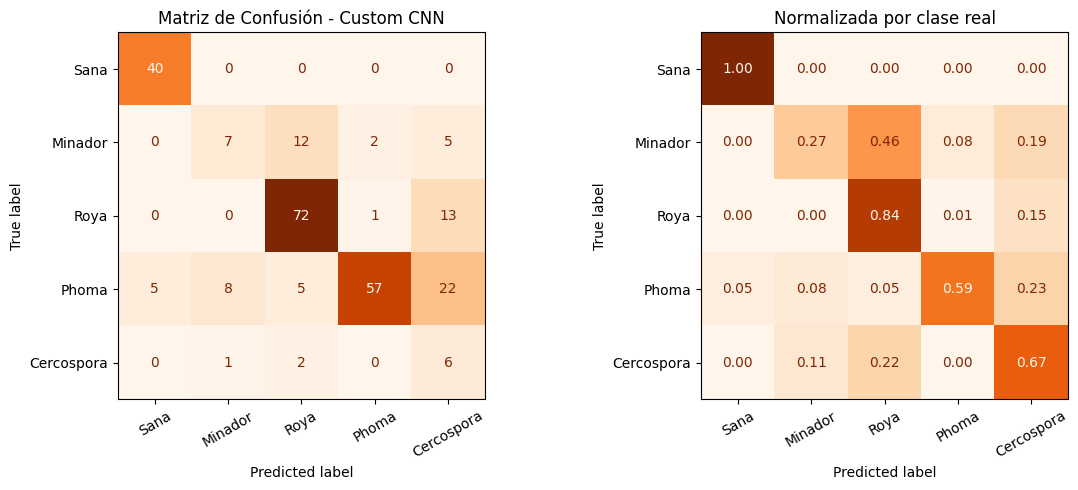

In [ ]:
custom_model.eval()
ys_c, ps_c = [], []
with torch.no_grad():
    for x, y in test_dl:
        ps_c += custom_model(x.to(DEVICE)).argmax(1).cpu().tolist()
        ys_c += y.tolist()

print("--- REPORTE CUSTOM CNN (DESDE CERO) ---")
print(classification_report(ys_c, ps_c, target_names=CLASSES, digits=3, zero_division=0))

# Comparación de matriz de confusión
cm_c = confusion_matrix(ys_c, ps_c)
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay(cm_c, display_labels=CLASSES).plot(ax=ax[0], cmap="Oranges", xticks_rotation=30, colorbar=False)
ConfusionMatrixDisplay(cm_c / (cm_c.sum(1, keepdims=True) + 1e-8), display_labels=CLASSES).plot(
    ax=ax[1], cmap="Oranges", xticks_rotation=30, values_format=".2f", colorbar=False)
ax[0].set_title("Matriz de Confusión - Custom CNN"); ax[1].set_title("Normalizada por clase real")
plt.tight_layout(); plt.savefig("matriz_confusion_custom.png", dpi=150); plt.show()

### Análisis de la comparación

| Métrica en test | ResNet-50 (preentrenada) | CNN desde cero |
|---|---|---|
| Accuracy | 0.798 | 0.690 |
| F1 macro | 0.717 | 0.585 |
| F1 ponderado | 0.816 | 0.681 |
| Recall Minador | 0.769 | 0.308 |
| Recall Roya | 0.860 | 0.523 |
| Recall Phoma | 0.691 | 0.845 |
| F1 Cercospora | 0.278 | 0.250 |
| Parámetros | 23.52 M | 0.25 M |

La ResNet-50 queda mejor: +10.8 puntos de accuracy y +13.2 de F1 macro. Además aprende mucho más rápido: en la primera época de fine-tuning ya tiene 0.81 de accuracy en validación, y la CNN desde cero llega a 0.69 en la época 15.

Lo que más se nota en la matriz de la CNN desde cero es que se va hacia Phoma. La predijo 129 veces de 258 (la mitad), cuando Phoma es solo el 38 % del test. El 62 % de los Minador y el 30 % de las Roya terminaron como Phoma. Parece que cuando no distingue, se queda con la clase más grande.

Por qué creemos que pasa: la ResNet ya trae filtros de ImageNet para bordes, colores y texturas, entonces solo los ajusta a las manchas del café. La CNN desde cero tiene que aprender todo con unas 1200 imágenes.

Cosas para tener en cuenta y que la comparación sea justa:

- La CNN solo se entrenó 15 épocas, sin scheduler ni early stopping, y todavía estaba mejorando (la pérdida de validación bajó hasta la época 14). Con más épocas la diferencia seguramente sería menor. Además el accuracy de train (0.563) quedó por debajo del de validación (0.690), entonces es más un caso de **underfitting** que de sobreajuste.
- No se puede decir que el preentrenamiento es la única causa. La ResNet también es unas 94 veces más grande (23.52 M contra 0.25 M de parámetros) y tiene BatchNorm y conexiones residuales, que la CNN no tiene.
- En Cercospora las dos fallan (F1 0.278 y 0.250). Ahí el problema son los pocos datos (65 imágenes) y no la arquitectura, y el transfer learning no lo arregló. Lo que sí mejoró mucho con la ResNet fue Minador y Roya.

## 10. Guardar resultados en Drive

In [ ]:
# copiamos el modelo y las figuras al drive para no perderlos
OUT = "/content/drive/MyDrive/proyecto_cafe"; os.makedirs(OUT, exist_ok=True)
for f in ["/content/best.pt", "curvas.png", "matriz_confusion.png", "matriz_confusion_custom.png", "gradcam_aciertos.png", "gradcam_errores.png", "demo.png"]:
    if os.path.exists(f): shutil.copy(f, OUT)
print("Guardado en", OUT)
if os.path.exists("/content/demo_imagenes"):
    shutil.copytree("/content/demo_imagenes", f"{OUT}/demo_imagenes", dirs_exist_ok=True)
    demo_res.to_csv(f"{OUT}/demo_resultados.csv", index=False)

Guardado en /content/drive/MyDrive/proyecto_cafe


## 11. Conclusiones

1. Con una ResNet-50 preentrenada y fine-tuning en dos fases se logró **79.8 % de accuracy y 0.717 de F1 macro** en test (258 imágenes, 5 clases: Sana, Minador, Roya, Phoma y Cercospora).
2. El transfer learning sí ayudó: la CNN hecha desde cero con las mismas condiciones sacó 69.0 % y 0.585 de F1 macro. Eso sí, esa CNN se entrenó pocas épocas, entonces la diferencia exacta hay que tomarla con cuidado.
3. Las hojas sanas se reconocen muy bien (recall 1.00) y Roya también (F1 0.881). Lo más difícil son las clases con manchas marrones parecidas (Phoma, Minador y Cercospora), que son las que más se confunden entre sí.
4. Cercospora es la clase débil (F1 0.278). Tiene muy pocas imágenes (65 en total, 9 en test) y aunque el peso de clase subió el recall (0.556), bajó la precisión (0.185). Con los datos que hay no se pudo resolver.
5. El Grad-CAM muestra que el modelo se fija en las lesiones y no en el fondo, tanto cuando acierta como cuando falla. Los errores parecen venir de manchas parecidas entre clases y de las hojas con varias enfermedades.
6. En las 25 imágenes de la demo acertó 84 %, parecido al test, pero con tan pocas imágenes sirve más para mostrar el modelo que para medirlo.
7. El entrenamiento es rápido (6.1 min en una T4), así que se puede reentrenar sin problema si se consiguen más datos.

### Limitaciones y trabajo futuro

- **Etiqueta única:** el 19 % de las hojas tiene más de una enfermedad y las dejamos con una sola (la de más área). Un enfoque multietiqueta sería más correcto.
- **Test chico:** 258 imágenes y solo 9 de Cercospora, las métricas de esa clase se mueven mucho.
- **Una sola corrida:** no se repitió con varias semillas, entonces no sabemos cuánto varían los resultados.
- **Mismos datos:** train, val, test y demo salen del mismo dataset (mismas condiciones de foto). No se probó con fotos de otra cámara o plantación, y en campo el rendimiento puede bajar.
- **Cercospora:** conseguir más imágenes, o probar focal loss o sobremuestreo, para ver si mejora.
- **Otras ideas:** probar otras arquitecturas (por ejemplo EfficientNet) y usar un umbral de confianza para que el modelo pueda decir "no estoy seguro".